# Лабораторная работа № 1. Линейная регрессия

**Задача:** предсказать `RiskScore` по `train.csv`, подготовить прогнозы для
`test.csv`. Основная метрика — **MSE**, требование соревнования — **MSE < 25**.
Реализованы обязательные задания из `cml_lab_1.pdf`. Дополнительные задания
с регуляризацией не выполняются. Другие модели не используются.

Ноутбук самостоятельный: все определения находятся в ячейках; рядом нужны
`train.csv`, `test.csv`, `ex.csv`. Запускать сверху вниз. В VS Code выбрать
Python из `.venv` этой папки; установка зависимостей описана в `README.md`.
`ex.csv` используется только для проверки формата отправки, не как правильные ответы.

In [1]:
from pathlib import Path
import json
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.linear_model import LinearRegression as SklearnLinearRegression, SGDRegressor
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             r2_score, mean_absolute_percentage_error)
from sklearn.preprocessing import StandardScaler, MinMaxScaler as SklearnMinMaxScaler
from sklearn.model_selection import train_test_split, cross_val_predict, LeaveOneOut

blas_limits = threadpool_limits(limits=1)
SEED = 42
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})

candidates = [Path.cwd(), Path.cwd() / "ML" / "lab-1",
              Path.cwd() / "ml" / "lab-1", Path.cwd() / "lab-1"]
DATA_DIR = next((p for p in candidates if (p / "train.csv").exists()
                 and (p / "test.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Откройте ноутбук из папки lab-1 или корня проекта.")
OUTPUT_DIR = DATA_DIR / "results"
OUTPUT_DIR.mkdir(exist_ok=True)

def show_figure(filename):
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

train_raw = pd.read_csv(DATA_DIR / "train.csv")
test_raw = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "ex.csv")
display(pd.DataFrame({"файл": ["train.csv", "test.csv", "ex.csv"],
                      "строк": [len(train_raw), len(test_raw), len(sample_submission)],
                      "столбцов": [train_raw.shape[1], test_raw.shape[1], sample_submission.shape[1]]}))
display(train_raw.head())

,файл,строк,столбцов
0,train.csv,11017,35
1,test.csv,5000,35
2,ex.csv,5000,2


,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,CreditCardUtilizationRate,NumberOfOpenCreditLines,NumberOfCreditInquiries,DebtToIncomeRatio,BankruptcyHistory,LoanPurpose,PreviousLoanDefaults,PaymentHistory,LengthOfCreditHistory,SavingsAccountBalance,CheckingAccountBalance,TotalAssets,TotalLiabilities,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,RiskScore
0,2010-06-26,27.0,66829.0,549.0,17290.0,60.0,Divorced,1.0,Rent,1095.0,0.151985,2.0,1.0,0.168542,0.0,Education,0.0,23.0,5.0,2539.0,247.0,50072.0,15005.0,5569.083333,0.908289,4.0,Employed,Associate,4.0,35067.0,0.257790,0.251465,508.970230,0.288013,66.176500
1,1996-09-23,55.0,172147.0,850.0,16110.0,36.0,Widowed,1.0,Mortgage,211.0,0.175693,3.0,0.0,0.141553,0.0,Home,0.0,27.0,11.0,844.0,694.0,91878.0,64877.0,14345.583333,0.797339,2.0,Employed,High School,33.0,27001.0,0.086110,0.093173,514.675859,0.050585,28.495737
2,2015-01-19,51.0,300000.0,850.0,38436.0,36.0,Married,0.0,Mortgage,546.0,0.444605,3.0,0.0,0.030987,1.0,Education,0.0,21.0,12.0,12756.0,651.0,292300.0,13918.0,25000.000000,0.915945,3.0,Employed,Bachelor,28.0,278382.0,0.108436,0.115443,1268.276385,0.072571,34.488104
3,1981-05-12,25.0,34683.0,847.0,19186.0,48.0,Married,0.0,Other,153.0,0.188452,7.0,0.0,0.379843,0.0,Debt Consolidation,0.0,27.0,21.0,1524.0,529.0,13070.0,3846.0,2890.250000,0.876416,3.0,Employed,High School,0.0,9224.0,0.100686,0.112822,498.505187,0.225415,36.910753
4,1995-05-07,55.0,300000.0,850.0,30437.0,48.0,Single,2.0,Rent,562.0,0.273431,3.0,1.0,0.068659,0.0,Debt Consolidation,0.0,35.0,9.0,1973.0,128.0,33357.0,351603.0,25000.000000,0.888689,5.0,Employed,Bachelor,31.0,4502.0,0.110437,0.089037,756.035156,0.052721,31.347091


## 1. Собственные алгоритмы

Определим метрики, обе нормализации и линейную регрессию. Все вычисления
обучения выполняются средствами NumPy. sklearn далее используется для сравнения.

\[
\mathrm{MSE}=\frac1n\sum_i(y_i-\hat y_i)^2,\qquad
\mathrm{MAE}=\frac1n\sum_i|y_i-\hat y_i|,
\]
\[
R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2},\qquad
\mathrm{MAPE}=\frac1n\sum_i\frac{|y_i-\hat y_i|}{\max(|y_i|,\varepsilon)}.
\]

MAPE возвращается как доля; в таблицах дополнительно показываем проценты.
При нулевых целях знаменатель заменяется машинным epsilon, как в sklearn.
Для постоянной цели R² равен 1 при точном прогнозе и 0 иначе; для одного
наблюдения он не определён.

Нормализации: $z=(x-\mu_{train})/\sigma_{train}$ и
$x'=(x-\min_{train})/(\max_{train}-\min_{train})$.
Константные столбцы обрабатываются без деления на ноль. Новые данные могут
выходить за диапазон [0, 1] после min-max — это корректно.

Модель: $\hat y=Xw+b$. Аналитическое решение $w=X_c^+y_c$ вычисляем
через SVD; $b=\bar y-\bar Xw$. Это устойчивый вариант аналитической формулы,
работающий и при зависимых столбцах, без регуляризации.
Для GD используем $\nabla L=2X_c^T(X_cw-y_c)/n$.
SGD обновляет веса по одному случайно выбранному наблюдению, проходя
перемешанную выборку в каждой эпохе. Свободный коэффициент во всех трёх
методах исключается аналитически через центрирование.

In [2]:
"""NumPy implementations for laboratory 1; no regularization is used.

The notebook contains the same definitions and can run without importing this
file.  This module also makes the numerical checks independently reproducible.
"""

from __future__ import annotations

import numpy as np


def _features(X):
    result = np.asarray(X, dtype=np.float64)
    if result.ndim != 2 or result.shape[0] == 0 or result.shape[1] == 0:
        raise ValueError("X must be a nonempty two-dimensional matrix.")
    if not np.isfinite(result).all():
        raise ValueError("X contains NaN or infinity; preprocess it first.")
    return result


def _target(y, n_samples=None):
    result = np.asarray(y, dtype=np.float64)
    if result.ndim != 1 or result.size == 0:
        raise ValueError("y must be a nonempty one-dimensional array.")
    if n_samples is not None and result.size != n_samples:
        raise ValueError("X and y have different numbers of samples.")
    if not np.isfinite(result).all():
        raise ValueError("y contains NaN or infinity.")
    return result


def _paired_targets(y_true, y_pred):
    actual = _target(y_true)
    predicted = _target(y_pred, actual.size)
    return actual, predicted

In [3]:
def mse(y_true, y_pred):
    """Mean squared error, in squared units of the target."""
    actual, predicted = _paired_targets(y_true, y_pred)
    return float(np.mean((actual - predicted) ** 2))


def mae(y_true, y_pred):
    """Mean absolute error, in units of the target."""
    actual, predicted = _paired_targets(y_true, y_pred)
    return float(np.mean(np.abs(actual - predicted)))


def r2(y_true, y_pred):
    """R squared with sklearn's default force_finite=True convention.

    For a constant target return 1 for an exact prediction and 0 otherwise.
    For fewer than two observations R squared is undefined (NaN).
    """
    actual, predicted = _paired_targets(y_true, y_pred)
    if actual.size < 2:
        return float("nan")
    numerator = float(np.sum((actual - predicted) ** 2))
    denominator = float(np.sum((actual - actual.mean()) ** 2))
    if denominator == 0.0:
        return 1.0 if numerator == 0.0 else 0.0
    return 1.0 - numerator / denominator


def mape(y_true, y_pred):
    """Relative MAPE, as in sklearn; multiply by 100 to obtain a percentage.

    Machine epsilon in the denominator makes the zero-target convention
    explicit. A value near zero in y_true can make this metric very large.
    """
    actual, predicted = _paired_targets(y_true, y_pred)
    denominator = np.maximum(np.abs(actual), np.finfo(np.float64).eps)
    return float(np.mean(np.abs(actual - predicted) / denominator))

In [4]:
class ZScoreScaler:
    """z = (x - training_mean) / training_std; population standard deviation."""

    def fit(self, X):
        values = _features(X)
        self.n_features_in_ = values.shape[1]
        self.mean_ = values.mean(axis=0)
        self.var_ = values.var(axis=0, ddof=0)
        self.scale_ = np.sqrt(self.var_)
        self.scale_ = np.where(self.scale_ == 0.0, 1.0, self.scale_)
        return self

    def transform(self, X):
        values = _features(X)
        if not hasattr(self, "mean_"):
            raise ValueError("Call fit before transform.")
        if values.shape[1] != self.n_features_in_:
            raise ValueError("The number of features differs from fit.")
        return (values - self.mean_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, X):
        values = _features(X)
        if not hasattr(self, "mean_"):
            raise ValueError("Call fit before inverse_transform.")
        if values.shape[1] != self.n_features_in_:
            raise ValueError("The number of features differs from fit.")
        return values * self.scale_ + self.mean_


class MinMaxScaler:
    """Scale to the training range [0, 1]; unseen values are not clipped."""

    def fit(self, X):
        values = _features(X)
        self.n_features_in_ = values.shape[1]
        self.data_min_ = values.min(axis=0)
        self.data_max_ = values.max(axis=0)
        self.data_range_ = self.data_max_ - self.data_min_
        safe_range = np.where(self.data_range_ == 0.0, 1.0, self.data_range_)
        self.scale_ = 1.0 / safe_range
        self.min_ = -self.data_min_ * self.scale_
        return self

    def transform(self, X):
        values = _features(X)
        if not hasattr(self, "scale_"):
            raise ValueError("Call fit before transform.")
        if values.shape[1] != self.n_features_in_:
            raise ValueError("The number of features differs from fit.")
        return values * self.scale_ + self.min_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, X):
        values = _features(X)
        if not hasattr(self, "scale_"):
            raise ValueError("Call fit before inverse_transform.")
        if values.shape[1] != self.n_features_in_:
            raise ValueError("The number of features differs from fit.")
        return (values - self.min_) / self.scale_

In [5]:
class LinearRegression:
    """Ordinary least squares trained analytically, with GD, or with SGD.

    ``max_iter`` counts gradient steps for GD and complete epochs for SGD.
    All three methods minimize mean squared error without regularization.
    With an intercept, X and y are centered using training statistics; the
    intercept is then recovered as mean(y) - mean(X) @ coef_. This eliminates
    the intercept analytically while preserving the least-squares objective.

    GD uses X.T @ X / n and X.T @ y / n as sufficient statistics. Its update
    is exactly the full-batch gradient, without rereading all n rows each step.
    SGD really visits individual shuffled observations, with a decreasing
    learning rate. ``loss_history_`` contains the initial loss and one loss
    per GD step / SGD epoch; ``n_iter_`` is the number of completed steps.
    """

    def __init__(
        self,
        method="analytic",
        learning_rate=None,
        max_iter=5000,
        tol=1e-9,
        random_state=42,
        fit_intercept=True,
    ):
        self.method = method
        self.learning_rate = learning_rate
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.fit_intercept = fit_intercept

    def fit(self, X, y):
        values = _features(X)
        target = _target(y, values.shape[0])
        if self.method not in {"analytic", "gd", "sgd"}:
            raise ValueError("method must be 'analytic', 'gd', or 'sgd'.")
        if not isinstance(self.max_iter, (int, np.integer)) or self.max_iter < 1:
            raise ValueError("max_iter must be a positive integer.")
        if not np.isfinite(self.tol) or self.tol < 0.0:
            raise ValueError("tol must be finite and nonnegative.")
        if self.learning_rate is not None and (
            not np.isfinite(self.learning_rate) or self.learning_rate <= 0.0
        ):
            raise ValueError("learning_rate must be positive and finite.")

        self.n_features_in_ = values.shape[1]
        self.x_mean_ = (
            values.mean(axis=0) if self.fit_intercept else np.zeros(values.shape[1])
        )
        self.y_mean_ = float(target.mean()) if self.fit_intercept else 0.0
        centered_X = np.ascontiguousarray(values - self.x_mean_)
        centered_y = target - self.y_mean_
        self.loss_history_ = [float(np.mean(centered_y**2))]
        self.converged_ = self.method == "analytic"
        self.n_iter_ = 0

        if self.method == "analytic":
            # Analytic formula w = X^+ y, X^+ = V S^+ U.T.
            # Unlike inverse(X.T @ X), it also handles collinear columns.
            left, self.singular_, right = np.linalg.svd(centered_X, full_matrices=False)
            cutoff = (
                np.finfo(np.float64).eps * max(centered_X.shape) * self.singular_[0]
            )
            retained = self.singular_ > cutoff
            self.rank_ = int(retained.sum())
            self.coef_ = right[retained].T @ (
                (left[:, retained].T @ centered_y) / self.singular_[retained]
            )
            self.loss_history_.append(mse(centered_y, centered_X @ self.coef_))
            self.n_iter_ = 1
        else:
            self.coef_ = self._fit_iterative(centered_X, centered_y)

        self.intercept_ = self.y_mean_ - float(self.x_mean_ @ self.coef_)
        self.training_mse_ = mse(target, self.predict(values))
        return self

    def _fit_iterative(self, X, y):
        n_samples, n_features = X.shape
        gram = X.T @ X / n_samples
        cross = X.T @ y / n_samples
        target_square = float(y @ y / n_samples)
        weights = np.zeros(n_features)

        def objective(current):
            # A tiny negative value can occur from cancellation near a perfect fit.
            return max(0.0, float(current @ gram @ current - 2 * current @ cross + target_square))

        if self.method == "gd":
            largest_eigenvalue = float(np.linalg.eigvalsh(gram)[-1])
            default_rate = 1.0 / (2.0 * max(largest_eigenvalue, 1e-15))
            self.learning_rate_ = (
                default_rate if self.learning_rate is None else float(self.learning_rate)
            )
            for iteration in range(self.max_iter):
                gradient = 2.0 * (gram @ weights - cross)
                weights -= self.learning_rate_ * gradient
                loss = objective(weights)
                if not np.isfinite(loss):
                    raise FloatingPointError("GD diverged; reduce learning_rate.")
                previous = self.loss_history_[-1]
                self.loss_history_.append(loss)
                self.n_iter_ = iteration + 1
                if abs(previous - loss) <= self.tol * max(1.0, previous):
                    self.converged_ = True
                    break
        else:
            generator = np.random.default_rng(self.random_state)
            largest_row_square = float(np.einsum("ij,ij->i", X, X).max())
            default_rate = min(0.01, 0.5 / max(largest_row_square, 1e-15))
            self.learning_rate_ = (
                default_rate if self.learning_rate is None else float(self.learning_rate)
            )
            updates = 0
            stable_epochs = 0
            best_loss = self.loss_history_[0]
            best_weights = weights.copy()
            for epoch in range(self.max_iter):
                for index in generator.permutation(n_samples):
                    # One observation, one gradient; no batch approximation.
                    eta = self.learning_rate_ / (1.0 + updates / n_samples) ** 0.75
                    error = float(X[index] @ weights - y[index])
                    weights -= 2.0 * eta * error * X[index]
                    updates += 1
                loss = objective(weights)
                if not np.isfinite(loss):
                    raise FloatingPointError("SGD diverged; reduce learning_rate.")
                previous = self.loss_history_[-1]
                self.loss_history_.append(loss)
                self.n_iter_ = epoch + 1
                if loss < best_loss:
                    best_loss, best_weights = loss, weights.copy()
                if abs(previous - loss) <= self.tol * max(1.0, previous):
                    stable_epochs += 1
                else:
                    stable_epochs = 0
                if stable_epochs >= 10:
                    self.converged_ = True
                    break
            # Retain the best complete epoch to avoid a final stochastic fluctuation.
            weights = best_weights
        return weights

    def predict(self, X):
        values = _features(X)
        if not hasattr(self, "coef_") or not hasattr(self, "intercept_"):
            raise ValueError("Call fit before predict.")
        if values.shape[1] != self.n_features_in_:
            raise ValueError("The number of features differs from fit.")
        return values @ self.coef_ + self.intercept_

In [6]:
def k_fold_indices(n_samples, n_splits=5, shuffle=True, random_state=42):
    """Yield each manual (train_indices, validation_indices) k-fold split."""
    if not isinstance(n_samples, (int, np.integer)) or n_samples < 2:
        raise ValueError("n_samples must be an integer >= 2.")
    if not isinstance(n_splits, (int, np.integer)) or not 2 <= n_splits <= n_samples:
        raise ValueError("n_splits must be between 2 and n_samples.")
    indices = np.arange(n_samples)
    if shuffle:
        indices = np.random.default_rng(random_state).permutation(indices)
    folds = np.array_split(indices, n_splits)
    for fold_number, validation in enumerate(folds):
        training = np.concatenate(
            [fold for number, fold in enumerate(folds) if number != fold_number]
        )
        yield training, validation


def leave_one_out_indices(n_samples):
    """Yield all n genuine leave-one-out train/validation partitions."""
    if not isinstance(n_samples, (int, np.integer)) or n_samples < 2:
        raise ValueError("n_samples must be an integer >= 2.")
    indices = np.arange(n_samples)
    for index in range(n_samples):
        yield np.concatenate((indices[:index], indices[index + 1 :])), indices[index : index + 1]


def loo_predictions_ols(X, y, fit_intercept=True):
    """Exact OLS leave-one-out predictions for a FIXED numeric design matrix.

    PRESS identity: prediction_LOO[i] = y[i] - residual[i] / (1 - leverage[i]).
    Leverages are the diagonal of the orthogonal projector onto the design
    column space, calculated from the retained left singular vectors. This
    also works for collinear columns when deletion preserves the rank.

    If 1 - leverage is almost zero, deletion can reduce the rank. Such cases
    are recomputed directly rather than dividing by zero. This function does
    NOT refit an imputer, encoder or scaler for each fold. To evaluate a whole
    preprocessing pipeline, use leave_one_out_indices and fit it per split.
    """
    values = _features(X)
    target = _target(y, values.shape[0])
    if target.size < 2:
        raise ValueError("LOO requires at least two observations.")
    design = (
        np.column_stack((np.ones(values.shape[0]), values))
        if fit_intercept
        else values
    )
    left, singular, _ = np.linalg.svd(design, full_matrices=False)
    cutoff = np.finfo(np.float64).eps * max(design.shape) * singular[0]
    retained = singular > cutoff
    basis = left[:, retained]
    fitted = basis @ (basis.T @ target)
    leverages = np.einsum("ij,ij->i", basis, basis)
    denominator = 1.0 - leverages
    predictions = np.empty_like(target)
    stable = denominator > 1e-10
    predictions[stable] = target[stable] - (target[stable] - fitted[stable]) / denominator[stable]
    for index in np.flatnonzero(~stable):
        keep = np.arange(target.size) != index
        model = LinearRegression(fit_intercept=fit_intercept).fit(values[keep], target[keep])
        predictions[index] = model.predict(values[index : index + 1])[0]
    return predictions

### Численная проверка метрик и нормализаций

Проверяем совпадение со sklearn, в том числе нулевую цель, постоянную цель
и константный признак. Это отдельные проверки формул, а не оценка модели.

In [7]:
metric_functions = {"MSE": (mse, mean_squared_error),
                    "MAE": (mae, mean_absolute_error),
                    "R2": (r2, r2_score),
                    "MAPE": (mape, mean_absolute_percentage_error)}
metric_checks = []
for case, actual, predicted in [
    ("обычные значения", [2., 4., 8., 10.], [2.5, 3., 8.2, 9.]),
    ("нулевая цель", [0., 1., 3.], [0.1, 1.2, 2.8]),
    ("постоянная цель", [5., 5., 5.], [5., 4., 6.]),
    ("точный прогноз константы", [5., 5., 5.], [5., 5., 5.]),
]:
    for name, (own, reference) in metric_functions.items():
        ours, theirs = own(actual, predicted), reference(actual, predicted)
        np.testing.assert_allclose(ours, theirs, rtol=1e-12, atol=1e-12)
        metric_checks.append({"случай": case, "метрика": name,
                              "своя": ours, "sklearn": theirs})
display(pd.DataFrame(metric_checks))

scaler_train = np.array([[1., 7., -2.], [3., 7., 0.], [8., 7., 4.]])
scaler_unseen = np.array([[12., 7., -5.], [2., 9., 1.]])
for own_cls, sklearn_cls in [(ZScoreScaler, StandardScaler),
                              (MinMaxScaler, SklearnMinMaxScaler)]:
    own, reference = own_cls().fit(scaler_train), sklearn_cls().fit(scaler_train)
    np.testing.assert_allclose(own.transform(scaler_train), reference.transform(scaler_train))
    np.testing.assert_allclose(own.transform(scaler_unseen), reference.transform(scaler_unseen))
    np.testing.assert_allclose(own.inverse_transform(own.transform(scaler_unseen)), scaler_unseen)
print("Метрики и обе нормализации совпали со sklearn.")

,случай,метрика,своя,sklearn
0,обычные значения,MSE,5.725000e-01,5.725000e-01
1,обычные значения,MAE,6.750000e-01,6.750000e-01
2,обычные значения,R2,9.427500e-01,9.427500e-01
3,обычные значения,MAPE,1.562500e-01,1.562500e-01
4,нулевая цель,MSE,3.000000e-02,3.000000e-02
5,нулевая цель,MAE,1.666667e-01,1.666667e-01
6,нулевая цель,R2,9.807143e-01,9.807143e-01
7,нулевая цель,MAPE,1.501200e+14,1.501200e+14
8,постоянная цель,MSE,6.666667e-01,6.666667e-01
9,постоянная цель,MAE,6.666667e-01,6.666667e-01


Метрики и обе нормализации совпали со sklearn.


## 2. Очистка и подготовка данных

Пустые строки не содержат наблюдений. Повторные строки удаляем **до** разбиения,
чтобы одна запись не оказалась одновременно в обучении и проверке.
Пропущенную цель не заполняем. Значения цели `-9999999` и `10000000` рассматриваем
как повреждённые записи: они изолированы на порядки от остального распределения.
Обычные большие значения денежных признаков автоматически не удаляем.

В отдельной группе строк одновременно отсутствуют девять полей. Такие строки
с повреждёнными входами исключаем; в `test.csv` этого блока пропусков нет.
Локальные оценки ниже относятся к оставшимся полным наблюдениям. Для будущих
неполных входов подготовка всё равно поддерживает заполнение медианами, но
качество на таких наблюдениях здесь не подтверждено.

Дата заявки и `ID` не используются как признаки. Категории кодируем one-hot
с удалением опорного уровня. Медианы, набор категорий, параметры преобразований
и нормализации определяются только на обучающей части каждого разбиения.

In [8]:
"""Train-only preprocessing for the linear-regression laboratory.

The engineered design is still linear in its learned coefficients. Logs,
polynomial terms, and binary interactions are deterministic feature maps;
no alternative prediction model or regularization is used.
"""

from __future__ import annotations

from itertools import combinations_with_replacement

import numpy as np
import pandas as pd



def clean_training_data(frame):
    """Remove objectively damaged observations and report each removal.

    The missing-data block affects nine predictors simultaneously. The test
    set is complete, so these damaged training observations are excluded;
    the preprocessor still supports imputation for future incomplete inputs.
    Valid large financial values are retained. The target cut only removes
    values of order ten million, separated from ordinary scores by five
    orders of magnitude; no quantile trimming of valid targets is performed.
    """
    if "RiskScore" not in frame:
        raise ValueError("The training frame must contain RiskScore.")
    data = frame.copy()
    audit = []

    def record(step, mask):
        nonlocal data
        removed = int(mask.sum())
        data = data.loc[~mask].copy()
        audit.append({"step": step, "removed": removed, "remaining": len(data)})

    audit.append({"step": "Исходные данные", "removed": 0, "remaining": len(data)})
    record("Полностью пустые строки", data.isna().all(axis=1))
    record("Полные дубли", data.duplicated())
    target = pd.to_numeric(data["RiskScore"], errors="coerce")
    record("Отсутствующая или явно повреждённая цель", ~np.isfinite(target) | target.abs().ge(1e6))
    predictors = data.drop(columns=["RiskScore", "ID"], errors="ignore")
    record("Повреждённые строки с блоком пропусков", predictors.isna().sum(axis=1).ge(9))
    return data.reset_index(drop=True), pd.DataFrame(audit)


class TabularPreprocessor:
    """Median imputation, one-hot encoding, and own z-score normalization.

    With ``engineered=True``, add logarithms of financial quantities and
    degree 2--4 polynomial terms over six influential quantitative fields.
    Their smooth nonlinear relationships are represented by a linear model
    over an expanded design matrix. The six polynomial inputs are clipped
    at training 0.1/99.9 percentiles before centering and scaling to prevent
    high monetary tails from exploding under fourth powers. Fixed feature
    definitions are reused for every split; all fitted values come from its
    training part only.
    """

    MONEY_COLUMNS = (
        "AnnualIncome", "LoanAmount", "MonthlyDebtPayments",
        "SavingsAccountBalance", "CheckingAccountBalance", "TotalAssets",
        "TotalLiabilities", "MonthlyIncome", "NetWorth", "MonthlyLoanPayment",
    )
    POLYNOMIAL_COLUMNS = (
        "CreditScore", "MonthlyIncome", "NetWorth",
        "TotalDebtToIncomeRatio", "InterestRate", "DebtToIncomeRatio",
    )
    LOG_POLYNOMIAL_COLUMNS = ("MonthlyIncome", "NetWorth", "TotalDebtToIncomeRatio")

    def __init__(self, engineered=False):
        self.engineered = bool(engineered)

    @staticmethod
    def _predictors(frame):
        if not isinstance(frame, pd.DataFrame):
            raise TypeError("Pass a pandas DataFrame with named columns.")
        return frame.drop(columns=["ID", "RiskScore", "ApplicationDate"], errors="ignore").copy()

    def _filled(self, frame):
        data = self._predictors(frame)
        missing_columns = set(self.input_columns_) - set(data.columns)
        if missing_columns:
            raise ValueError(f"Missing input columns: {sorted(missing_columns)}")
        data = data.loc[:, self.input_columns_]
        for col in self.numeric_columns_:
            data[col] = pd.to_numeric(data[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
            data[col] = data[col].fillna(self.medians_[col])
        for col in self.categorical_columns_:
            data[col] = data[col].astype("string").fillna("__missing__")
        return data

    def _polynomial_inputs(self, data):
        inputs = data.loc[:, self.POLYNOMIAL_COLUMNS].copy()
        for col in self.LOG_POLYNOMIAL_COLUMNS:
            inputs[col] = np.log1p(inputs[col].clip(lower=0))
        return inputs

    def _design(self, data):
        columns = {col: data[col].to_numpy(dtype=float) for col in self.numeric_columns_}
        for col, levels in self.categories_.items():
            # Dropping the first training category avoids the dummy-variable trap.
            # An unseen category maps to zero in every dummy of this field.
            for level in levels[1:]:
                columns[f"{col}={level}"] = data[col].eq(level).to_numpy(dtype=float)
        if self.engineered:
            for col in self.MONEY_COLUMNS:
                columns[f"log1p({col})"] = np.log1p(data[col].clip(lower=0).to_numpy(dtype=float))
            columns["DTI_capped_1"] = data["TotalDebtToIncomeRatio"].clip(upper=1).to_numpy(dtype=float)
            poly = self._polynomial_inputs(data)
            poly = poly.clip(lower=self.poly_lower_, upper=self.poly_upper_, axis=1)
            values = (poly.to_numpy(dtype=float) - self.poly_mean_) / self.poly_scale_
            for indices in self.polynomial_terms_:
                label = " * ".join(self.POLYNOMIAL_COLUMNS[i] for i in indices)
                columns[f"poly({label})"] = np.prod(values[:, indices], axis=1)
            indicators = {
                "BankruptcyHistory": data["BankruptcyHistory"].to_numpy(dtype=float),
                "PreviousLoanDefaults": data["PreviousLoanDefaults"].to_numpy(dtype=float),
                "Unemployed": data["EmploymentStatus"].eq("Unemployed").to_numpy(dtype=float),
                "SelfEmployed": data["EmploymentStatus"].eq("Self-Employed").to_numpy(dtype=float),
            }
            for indicator_name, flag in indicators.items():
                for j, col in enumerate(self.POLYNOMIAL_COLUMNS):
                    columns[f"{indicator_name} * scaled({col})"] = flag * values[:, j]
        result = pd.DataFrame(columns, index=data.index)
        return result

    def fit(self, frame):
        raw = self._predictors(frame)
        if raw.empty:
            raise ValueError("Cannot fit preprocessing on an empty frame.")
        self.input_columns_ = list(raw.columns)
        self.numeric_columns_ = list(raw.select_dtypes(include="number").columns)
        self.categorical_columns_ = [col for col in raw if col not in self.numeric_columns_]
        self.medians_ = raw[self.numeric_columns_].replace([np.inf, -np.inf], np.nan).median().fillna(0)
        data = self._filled(frame)
        self.categories_ = {
            col: sorted(data[col].unique().tolist())
            for col in self.categorical_columns_
        }
        if self.engineered:
            poly = self._polynomial_inputs(data)
            self.poly_lower_ = poly.quantile(0.001)
            self.poly_upper_ = poly.quantile(0.999)
            poly = poly.clip(lower=self.poly_lower_, upper=self.poly_upper_, axis=1)
            self.poly_mean_ = poly.to_numpy(dtype=float).mean(axis=0)
            self.poly_scale_ = poly.to_numpy(dtype=float).std(axis=0)
            self.poly_scale_[self.poly_scale_ == 0] = 1.0
            self.polynomial_terms_ = [
                indices
                for degree in range(2, 5)
                for indices in combinations_with_replacement(range(len(self.POLYNOMIAL_COLUMNS)), degree)
            ]
        design = self._design(data)
        self.feature_names_ = list(design.columns)
        self.scaler_ = ZScoreScaler().fit(design.to_numpy(dtype=float))
        return self

    def transform(self, frame):
        if not hasattr(self, "scaler_"):
            raise ValueError("Call fit before transform.")
        design = self._design(self._filled(frame))
        return self.scaler_.transform(design.loc[:, self.feature_names_].to_numpy(dtype=float))

    def fit_transform(self, frame):
        return self.fit(frame).transform(frame)

In [9]:
clean, cleaning_audit = clean_training_data(train_raw)
display(cleaning_audit)
raw_unique = train_raw.dropna(how="all").drop_duplicates()
display(raw_unique.isna().sum().loc[lambda counts: counts > 0].to_frame("пропуски до очистки"))
display(pd.DataFrame({"тип": clean.dtypes.astype(str),
                      "пропусков": clean.isna().sum(),
                      "уникальных": clean.nunique()}))
print("Оставшиеся значения RiskScore:", clean.RiskScore.min(), "…", clean.RiskScore.max())
assert "RiskScore" not in test_raw.columns
assert test_raw.ID.is_unique
assert list(sample_submission.columns) == ["ID", "RiskScore"]

,step,removed,remaining
0,Исходные данные,0,11017
1,Полностью пустые строки,530,10487
2,Полные дубли,487,10000
3,Отсутствующая или явно повреждённая цель,212,9788
4,Повреждённые строки с блоком пропусков,456,9332


,пропуски до очистки
CreditScore,471
LoanAmount,471
MonthlyDebtPayments,471
BankruptcyHistory,471
LoanPurpose,471
CheckingAccountBalance,471
TotalAssets,471
NetWorth,471
BaseInterestRate,471


,тип,пропусков,уникальных
ApplicationDate,str,0,9332
Age,float64,0,63
AnnualIncome,float64,0,5222
CreditScore,float64,0,548
LoanAmount,float64,0,8558
LoanDuration,float64,0,10
MaritalStatus,str,0,4
NumberOfDependents,float64,0,7
HomeOwnershipStatus,str,0,4
MonthlyDebtPayments,float64,0,1726


Оставшиеся значения RiskScore: 14.841417296887238 … 97.59724939432462


## 3. Разведочный анализ (EDA)

Матрица корреляций содержит числовые признаки. Пропуски здесь учитываются
попарно средствами pandas; статистики EDA не используются для заполнения
проверочной выборки. На графиках показана очищенная выборка.

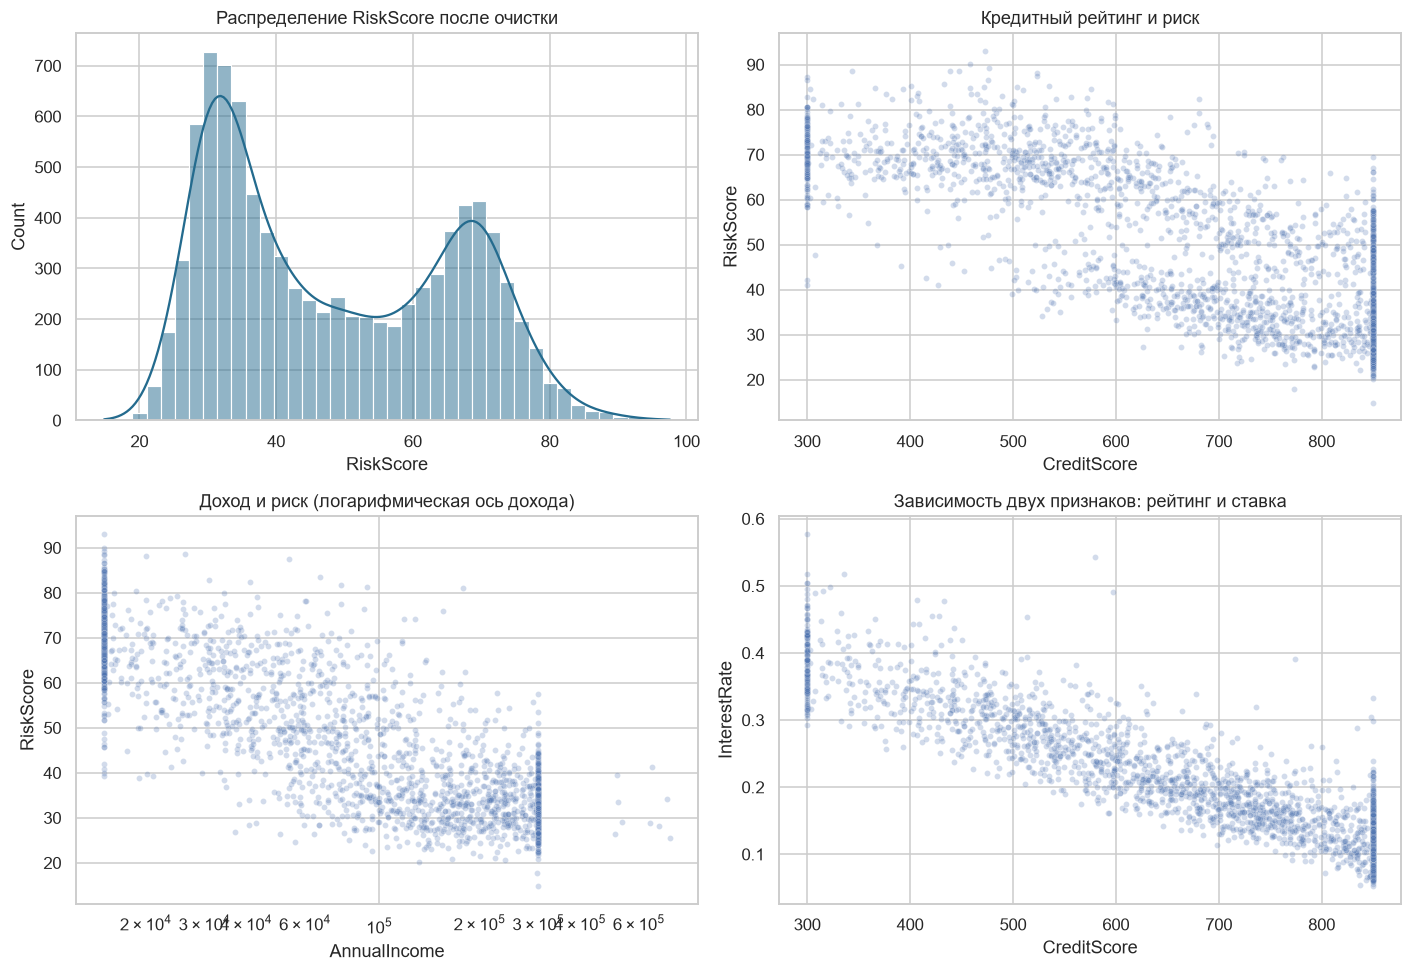

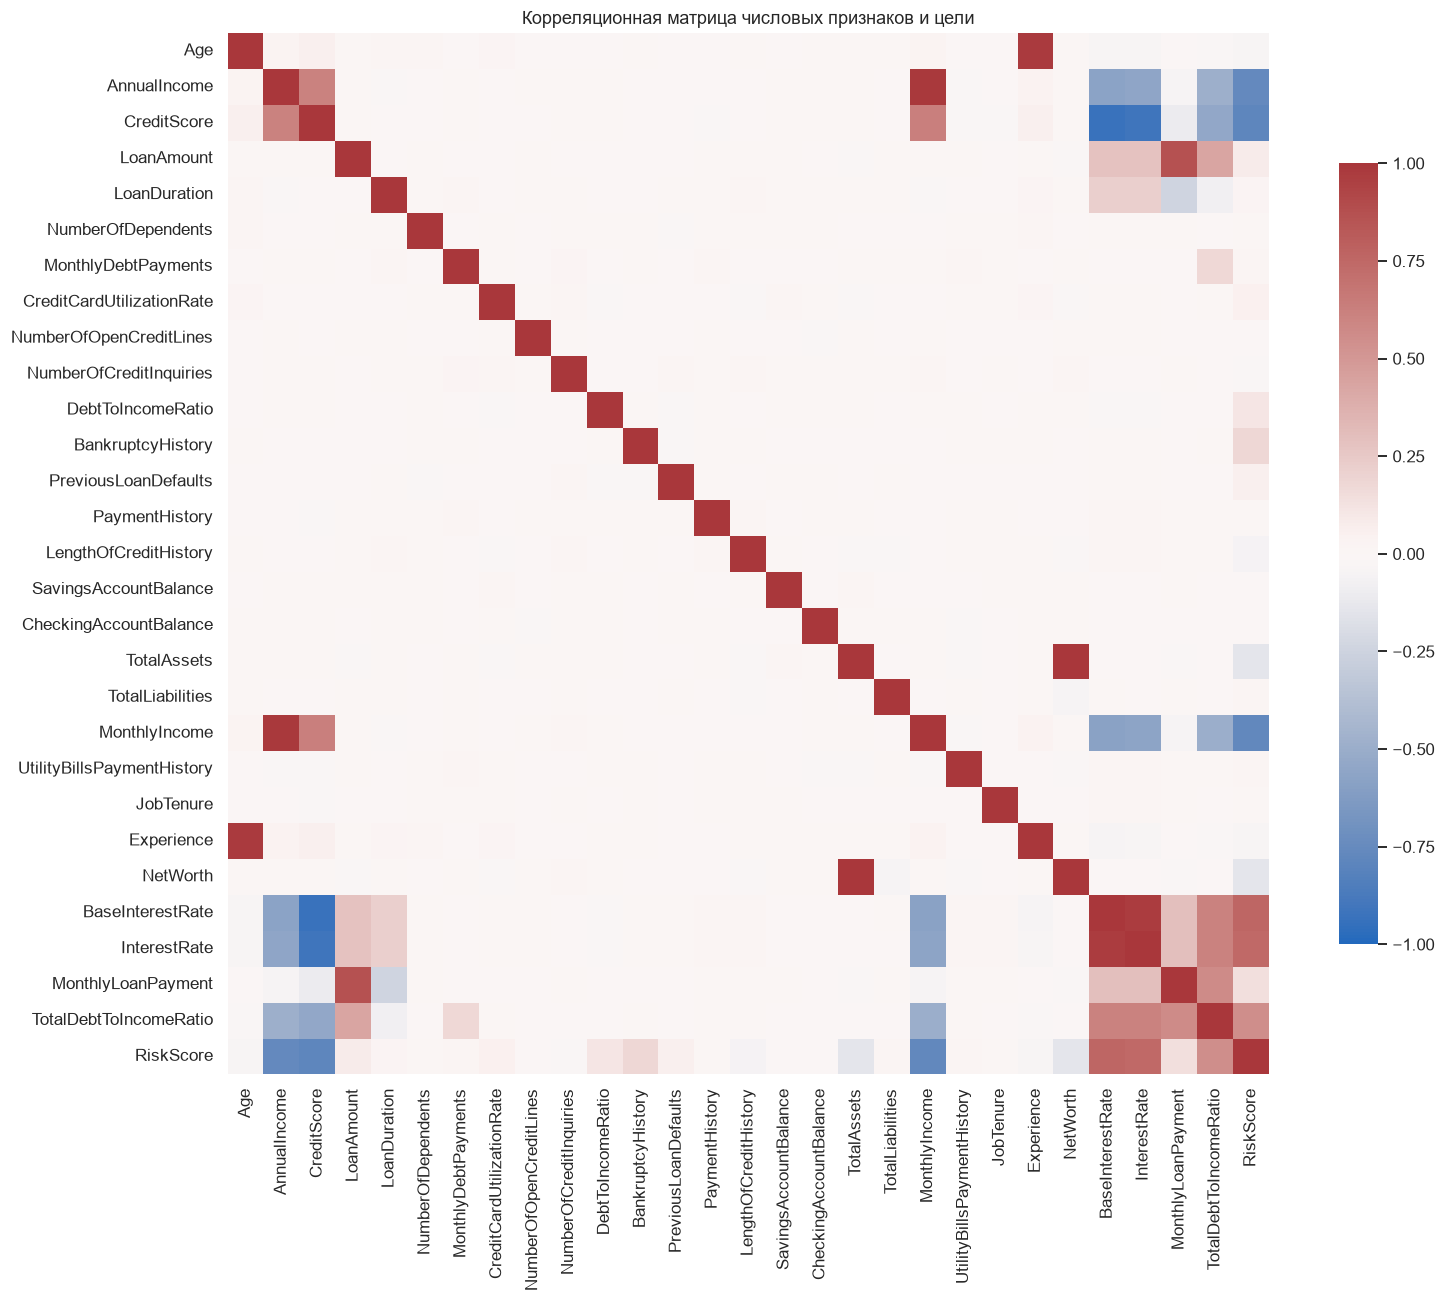

,корреляция с RiskScore
CreditScore,-0.785429
MonthlyIncome,-0.770341
BaseInterestRate,0.759546
AnnualIncome,-0.757874
InterestRate,0.744193
TotalDebtToIncomeRatio,0.554352
BankruptcyHistory,0.179697
TotalAssets,-0.147472
MonthlyLoanPayment,0.147417
NetWorth,-0.146222


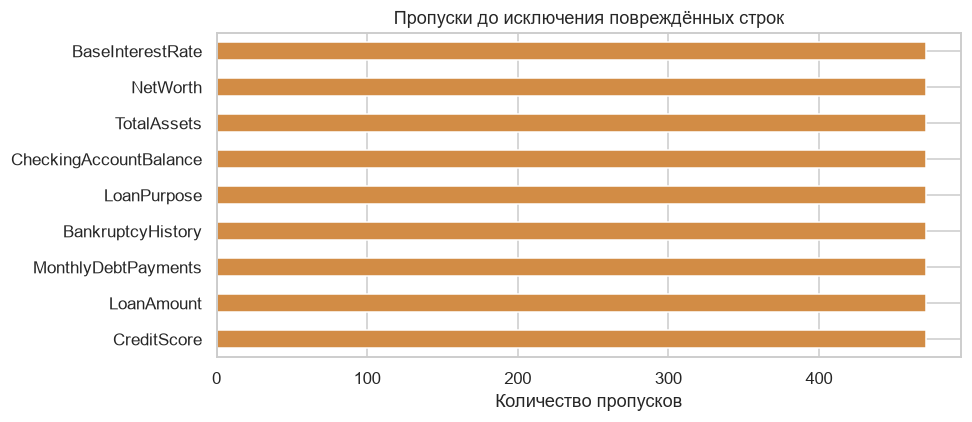

**Выводы EDA.** Наибольшая по модулю линейная корреляция с целью у `CreditScore` (-0.785). У денежных величин разные масштабы и длинные правые хвосты. Часть финансовых показателей связана между собой, поэтому матрица может быть вырожденной; аналитическое решение вычисляется через псевдообратную. На графиках видны зависимости, которые одна прямая описывает неполно. Корреляция сама по себе не доказывает причинное влияние.

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(clean.RiskScore, bins=40, kde=True, ax=axes[0, 0], color="#246b8e")
axes[0, 0].set_title("Распределение RiskScore после очистки")
plot_sample = clean.sample(n=min(2500, len(clean)), random_state=SEED)
sns.scatterplot(data=plot_sample, x="CreditScore", y="RiskScore",
                alpha=.25, s=15, ax=axes[0, 1])
axes[0, 1].set_title("Кредитный рейтинг и риск")
sns.scatterplot(data=plot_sample, x="AnnualIncome", y="RiskScore",
                alpha=.25, s=15, ax=axes[1, 0])
axes[1, 0].set_xscale("log")
axes[1, 0].set_title("Доход и риск (логарифмическая ось дохода)")
sns.scatterplot(data=plot_sample, x="CreditScore", y="InterestRate",
                alpha=.25, s=15, ax=axes[1, 1])
axes[1, 1].set_title("Зависимость двух признаков: рейтинг и ставка")
show_figure("eda_distributions.png")

correlations = clean.select_dtypes(include="number").corr()
plt.figure(figsize=(15, 12))
sns.heatmap(correlations, cmap="vlag", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": .75})
plt.title("Корреляционная матрица числовых признаков и цели")
show_figure("correlation_matrix.png")
target_correlations = correlations.RiskScore.drop("RiskScore")
display(target_correlations.reindex(target_correlations.abs().sort_values(ascending=False).index)
        .head(12).to_frame("корреляция с RiskScore"))

missing_counts = raw_unique.isna().sum().loc[lambda counts: counts > 0].sort_values()
if not missing_counts.empty:
    missing_counts.plot.barh(figsize=(9, 4), color="#d28c45")
    plt.xlabel("Количество пропусков")
    plt.title("Пропуски до исключения повреждённых строк")
    show_figure("missing_values.png")
strongest = target_correlations.abs().idxmax()
display(Markdown(
    f"**Выводы EDA.** Наибольшая по модулю линейная корреляция с целью у "
    f"`{strongest}` ({target_correlations[strongest]:.3f}). "
    "У денежных величин разные масштабы и длинные правые хвосты. "
    "Часть финансовых показателей связана между собой, поэтому матрица может быть "
    "вырожденной; аналитическое решение вычисляется через псевдообратную. "
    "На графиках видны зависимости, которые одна прямая описывает неполно. "
    "Корреляция сама по себе не доказывает причинное влияние."
))

## 4. Отложенная выборка и сравнение способов обучения

Выделяем 20% строк для проверки. На одинаковых исходных признаках сравниваем
аналитику, полный GD, настоящий SGD и реализации sklearn. Это базовый вариант
без дополнительных базисных признаков. Итоговую улучшенную модель исследуем
отдельно. Выбор шага и остановка итераций не используют проверочные ответы.

Обучение: (7465, 44) Проверка: (1867, 44)


,MSE,MAE,R2,"MAPE, %",MSE train,итераций/эпох,секунд
модель,,,,,,,
своя analytic,49.495788,5.645597,0.834709,13.101285,50.320874,1.0,0.011755
своя gd,49.496138,5.645640,0.834707,13.101437,50.320876,4452.0,0.031993
своя sgd,49.716983,5.664769,0.833970,13.153924,50.408448,250.0,3.675140
sklearn LinearRegression,49.495788,5.645597,0.834709,13.101285,50.320874,NaN,NaN
"sklearn SGDRegressor, penalty=None",49.705361,5.664165,0.834009,13.148190,50.399877,1400.0,NaN


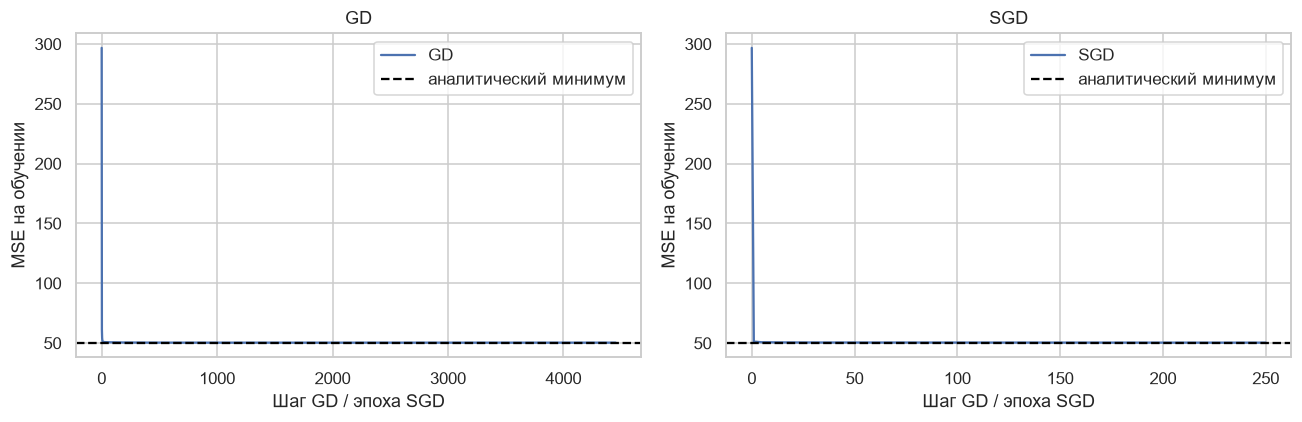

,MSE,MAE,R2,"MAPE, %"
нормализация,,,,
z-score,49.495788,5.645597,0.834709,13.101285
min-max,49.495788,5.645597,0.834709,13.101285


In [11]:
X = clean.drop(columns="RiskScore")
y = clean.RiskScore.to_numpy(dtype=float)
train_indices, valid_indices = train_test_split(np.arange(len(clean)), test_size=.2, random_state=SEED)
X_train_raw, X_valid_raw = X.iloc[train_indices], X.iloc[valid_indices]
y_train, y_valid = y[train_indices], y[valid_indices]
baseline_preprocessor = TabularPreprocessor(engineered=False)
X_train = baseline_preprocessor.fit_transform(X_train_raw)
X_valid = baseline_preprocessor.transform(X_valid_raw)
print("Обучение:", X_train.shape, "Проверка:", X_valid.shape)

def scores(actual, predicted):
    return {"MSE": mse(actual, predicted), "MAE": mae(actual, predicted),
            "R2": r2(actual, predicted), "MAPE, %": 100 * mape(actual, predicted)}

baseline_models = {}
comparison_rows = []
for method, iterations in [("analytic", 1), ("gd", 20000), ("sgd", 250)]:
    started = perf_counter()
    model = LinearRegression(method=method, max_iter=iterations, tol=1e-10, random_state=SEED)
    model.fit(X_train, y_train)
    elapsed = perf_counter() - started
    baseline_models[method] = model
    comparison_rows.append({"модель": "своя " + method,
                            **scores(y_valid, model.predict(X_valid)),
                            "MSE train": mse(y_train, model.predict(X_train)),
                            "итераций/эпох": model.n_iter_, "секунд": elapsed})

reference_ols = SklearnLinearRegression().fit(X_train, y_train)
np.testing.assert_allclose(baseline_models["analytic"].predict(X_valid),
                           reference_ols.predict(X_valid), rtol=1e-8, atol=1e-7)
comparison_rows.append({"модель": "sklearn LinearRegression",
                        **scores(y_valid, reference_ols.predict(X_valid)),
                        "MSE train": mean_squared_error(y_train, reference_ols.predict(X_train))})
reference_sgd = SGDRegressor(penalty=None, loss="squared_error", max_iter=10000,
                             tol=1e-5, random_state=SEED, learning_rate="adaptive",
                             eta0=min(.001, baseline_models["sgd"].learning_rate_),
                             average=True)
reference_sgd.fit(X_train, y_train)
comparison_rows.append({"модель": "sklearn SGDRegressor, penalty=None",
                        **scores(y_valid, reference_sgd.predict(X_valid)),
                        "MSE train": mean_squared_error(y_train, reference_sgd.predict(X_train)),
                        "итераций/эпох": reference_sgd.n_iter_})
optimizer_comparison = pd.DataFrame(comparison_rows).set_index("модель")
display(optimizer_comparison)
optimizer_comparison.to_csv(OUTPUT_DIR / "optimizer_comparison.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, method in zip(axes, ["gd", "sgd"]):
    history = baseline_models[method].loss_history_
    axis.plot(np.arange(len(history)), history, label=method.upper())
    axis.axhline(baseline_models["analytic"].training_mse_, color="black",
                 linestyle="--", label="аналитический минимум")
    axis.set(xlabel="Шаг GD / эпоха SGD", ylabel="MSE на обучении", title=method.upper())
    axis.legend()
show_figure("optimizer_convergence.png")

normalization_rows = []
for name, scaler in [("z-score", ZScoreScaler()), ("min-max", MinMaxScaler())]:
    normalized_train = scaler.fit_transform(X_train)
    normalized_valid = scaler.transform(X_valid)
    normalized_model = LinearRegression().fit(normalized_train, y_train)
    normalization_rows.append({"нормализация": name,
                                **scores(y_valid, normalized_model.predict(normalized_valid))})
display(pd.DataFrame(normalization_rows).set_index("нормализация"))

GD и SGD решают ту же задачу минимизации MSE, что аналитический метод,
но за конечное число итераций могут не достичь его результата. Зависимые
признаки допускают разные наборы весов с одинаковыми прогнозами, поэтому
сравниваем прогнозы и ошибки, а не требуем совпадения весов.

При наличии свободного коэффициента обратимое изменение масштаба признаков
не меняет пространство прогнозов OLS. Поэтому аналитика с z-score и min-max
даёт практически одинаковую ошибку. Для скорости GD и SGD масштабирование существенно.

## 5. Подготовка улучшенных признаков

Дополнительные признаки — детерминированные преобразования входных данных.
Они могут описывать нелинейную зависимость от исходного столбца, но модель
остаётся **линейной по обучаемым весам**: $\hat y=\sum_j w_j\phi_j(x)+b$.
Другие обучаемые модели и регуляризация не используются.
Добавлены логарифмы денежных величин, полиномиальные члены степеней 2–4
по шести исходным величинам и взаимодействия с признаками банкротства,
предыдущих дефолтов и занятости. Перед возведением в степень входы полиномов
ограничиваются обучающими квантилями 0.1% и 99.9%, затем центрируются
и масштабируются. Это ограничение применяется к базисным признакам;
наблюдения и обычные исходные денежные величины сохраняются.
Точный набор преобразований и их вычисление приведены в `TabularPreprocessor`
выше. Все параметры, требующие оценки по данным, переобучаются внутри каждого fold.

,MSE,MAE,R2,"MAPE, %",столбцов
признаки,,,,,
исходные + one-hot,49.495788,5.645597,0.834709,13.101285,44
преобразованные + one-hot,23.347188,3.614111,0.922032,8.326233,282


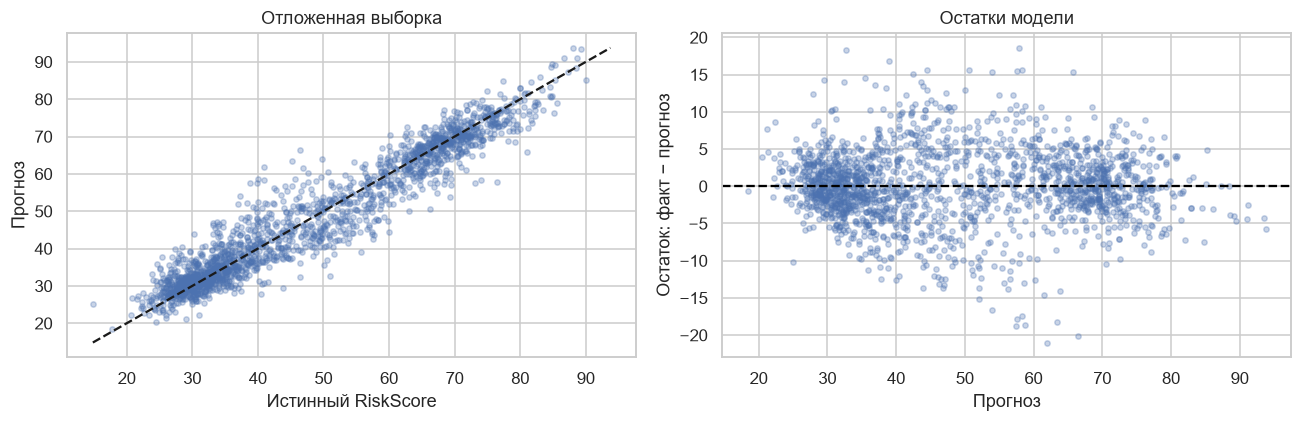

In [12]:
improved_preprocessor = TabularPreprocessor(engineered=True)
X_train_improved = improved_preprocessor.fit_transform(X_train_raw)
X_valid_improved = improved_preprocessor.transform(X_valid_raw)
improved_model = LinearRegression().fit(X_train_improved, y_train)
improved_predictions = improved_model.predict(X_valid_improved)
holdout_scores = scores(y_valid, improved_predictions)
feature_comparison = pd.DataFrame([
    {"признаки": "исходные + one-hot", **scores(y_valid, baseline_models["analytic"].predict(X_valid)),
     "столбцов": X_train.shape[1]},
    {"признаки": "преобразованные + one-hot", **holdout_scores,
     "столбцов": X_train_improved.shape[1]},
]).set_index("признаки")
display(feature_comparison)
feature_comparison.to_csv(OUTPUT_DIR / "feature_comparison.csv")
np.testing.assert_allclose(improved_predictions,
                           SklearnLinearRegression().fit(X_train_improved, y_train).predict(X_valid_improved),
                           rtol=1e-7, atol=1e-6)
for name, (own, reference) in metric_functions.items():
    np.testing.assert_allclose(own(y_valid, improved_predictions),
                               reference(y_valid, improved_predictions), rtol=1e-12, atol=1e-12)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_valid, improved_predictions, alpha=.3, s=12)
limits = [min(y_valid.min(), improved_predictions.min()), max(y_valid.max(), improved_predictions.max())]
axes[0].plot(limits, limits, "k--")
axes[0].set(xlabel="Истинный RiskScore", ylabel="Прогноз", title="Отложенная выборка")
axes[1].scatter(improved_predictions, y_valid - improved_predictions, alpha=.3, s=12)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="Прогноз", ylabel="Остаток: факт − прогноз", title="Остатки модели")
show_figure("validation_predictions.png")

## 6. Самостоятельная k-fold кросс-валидация

Пять непересекающихся проверочных частей; каждая строка ровно один раз служит
проверочной. На каждой итерации заново обучаем всю подготовку и модель.
Сравниваем базовый и улучшенный варианты на одних разбиениях. OOF-метрики
считаются по всем прогнозам вне обучения; среднее MSE fold приводится отдельно.

In [13]:
def evaluate_splits(frame, target, splits, engineered):
    predictions = np.full(len(target), np.nan)
    visits = np.zeros(len(target), dtype=int)
    rows = []
    for fold, (training, validation) in enumerate(splits, start=1):
        assert not np.intersect1d(training, validation).size
        preprocessor = TabularPreprocessor(engineered=engineered)
        train_design = preprocessor.fit_transform(frame.iloc[training])
        valid_design = preprocessor.transform(frame.iloc[validation])
        model = LinearRegression().fit(train_design, target[training])
        predicted = model.predict(valid_design)
        predictions[validation] = predicted
        visits[validation] += 1
        rows.append({"fold": fold, "train": len(training), "validation": len(validation),
                     **scores(target[validation], predicted)})
    assert np.all(visits == 1), "Каждая строка должна быть проверена ровно один раз"
    assert np.isfinite(predictions).all()
    return predictions, pd.DataFrame(rows)

kfold_results, oof_predictions = [], {}
for engineered, label in [(False, "исходные"), (True, "преобразованные")]:
    predicted, fold_table = evaluate_splits(
        X, y, k_fold_indices(len(y), n_splits=5, random_state=SEED), engineered=engineered)
    oof_predictions[label] = predicted
    fold_table.insert(0, "признаки", label)
    kfold_results.append(fold_table)
kfold_table = pd.concat(kfold_results, ignore_index=True)
display(kfold_table)
cv_summary = pd.DataFrame([
    {"признаки": label, **scores(y, predicted),
     "среднее MSE fold": kfold_table.loc[kfold_table["признаки"] == label, "MSE"].mean(),
     "std MSE fold": kfold_table.loc[kfold_table["признаки"] == label, "MSE"].std(ddof=1)}
    for label, predicted in oof_predictions.items()
]).set_index("признаки")
display(cv_summary)
kfold_table.to_csv(OUTPUT_DIR / "kfold_scores.csv", index=False)
cv_summary.to_csv(OUTPUT_DIR / "cross_validation_summary.csv")

,признаки,fold,train,validation,MSE,MAE,R2,"MAPE, %"
0,исходные,1,7465,1867,50.952251,5.717537,0.827127,13.588762
1,исходные,2,7465,1867,49.966294,5.664630,0.833488,13.312564
2,исходные,3,7466,1866,47.091107,5.534460,0.841277,12.908331
3,исходные,4,7466,1866,54.903655,5.952725,0.812847,14.034466
4,исходные,5,7466,1866,49.940057,5.704119,0.834375,13.248256
5,преобразованные,1,7465,1867,22.559665,3.572868,0.923459,8.260792
6,преобразованные,2,7465,1867,24.178691,3.661836,0.919425,8.365759
7,преобразованные,3,7466,1866,24.568643,3.626784,0.917190,8.344718
8,преобразованные,4,7466,1866,24.283973,3.682762,0.917222,8.447865
9,преобразованные,5,7466,1866,23.400911,3.625331,0.922391,8.435716


,MSE,MAE,R2,"MAPE, %",среднее MSE fold,std MSE fold
признаки,,,,,,
исходные,50.570649,5.714689,0.829896,13.418483,50.570673,2.819161
преобразованные,23.798285,3.633913,0.919950,8.370957,23.798377,0.816416


## 7. Самостоятельная leave-one-out кросс-валидация

**Полный пересчёт подготовки.** Для демонстрации обычного алгоритма берём
случайную подвыборку из 200 строк: 200 раз исключаем одну строку и заново
обучаем подготовку и модель на остальных 199. Здесь используем исходные
признаки: при 199 наблюдениях большой базис был бы избыточным.
Это именно LOO на подвыборке, а не оценка LOO на всех данных.

**Дополнительный быстрый расчёт.** На всей фиксированной числовой матрице
можно вычислить LOO аналитической OLS по формуле PRESS:
$\hat y_i^{(-i)}=y_i-e_i/(1-h_{ii})$.
Эта формула исключает строку из обучения регрессии, но не переобучает медианы
и кодирование. Поэтому результат явно обозначен как LOO **фиксированной матрицы**,
а основной оценкой полного решения служит k-fold выше. Диагональ проектора
получаем через SVD, не создавая матрицу размера $n\times n$.

In [14]:
loo_indices = np.random.default_rng(SEED).choice(len(y), size=200, replace=False)
loo_frame = X.iloc[loo_indices].reset_index(drop=True)
loo_y = y[loo_indices]
loo_pipeline_predictions, _ = evaluate_splits(
    loo_frame, loo_y, leave_one_out_indices(len(loo_y)), engineered=False)
display(pd.DataFrame([{"вариант": "полный refit подготовки, 200 строк",
                       **scores(loo_y, loo_pipeline_predictions)}]).set_index("вариант"))

# Independent check: own PRESS and literal sklearn LOO on exactly the same design.
check_rng = np.random.default_rng(SEED)
check_design = check_rng.normal(size=(35, 5))
check_design = np.column_stack([check_design, check_design[:, 0] + check_design[:, 1]])
check_y = check_design @ check_rng.normal(size=6) + check_rng.normal(scale=.1, size=35)
check_press = loo_predictions_ols(check_design, check_y)
check_direct = cross_val_predict(SklearnLinearRegression(), check_design, check_y, cv=LeaveOneOut())
np.testing.assert_allclose(check_press, check_direct, rtol=1e-8, atol=1e-8)
print("PRESS совпал с буквальным sklearn LeaveOneOut, в том числе при зависимых столбцах.")

full_fixed_preprocessor = TabularPreprocessor(engineered=True)
full_fixed_design = full_fixed_preprocessor.fit_transform(X)
press_predictions = loo_predictions_ols(full_fixed_design, y)
press_scores = scores(y, press_predictions)
display(pd.DataFrame([{"вариант": "PRESS: фиксированная матрица, все строки",
                       **press_scores}]).set_index("вариант"))

,MSE,MAE,R2,"MAPE, %"
вариант,,,,
"полный refit подготовки, 200 строк",77.073452,6.915123,0.754879,15.683609


PRESS совпал с буквальным sklearn LeaveOneOut, в том числе при зависимых столбцах.


,MSE,MAE,R2,"MAPE, %"
вариант,,,,
"PRESS: фиксированная матрица, все строки",23.560731,3.611815,0.920749,8.32283


## 8. Итоговое обучение и файл для Kaggle

После проверки обучаем подготовку и аналитическую линейную регрессию на всех
очищенных размеченных строках. `test.csv` не участвует в оценке параметров
подготовки. Порядок строк и `ID` сохраняются. Прогнозы не ограничиваем искусственно.

Локальные MSE и кросс-валидация не являются результатом Kaggle. Проверка условия
**MSE < 25 на соревновании** возможна после загрузки `submission.csv`.

In [15]:
final_preprocessor = TabularPreprocessor(engineered=True)
final_design = final_preprocessor.fit_transform(X)
final_model = LinearRegression().fit(final_design, y)
test_design = final_preprocessor.transform(test_raw.drop(columns="ID"))
test_predictions = final_model.predict(test_design)
submission = pd.DataFrame({"ID": test_raw.ID.to_numpy(), "RiskScore": test_predictions})
assert submission.shape == sample_submission.shape
assert list(submission.columns) == list(sample_submission.columns)
assert submission.ID.equals(test_raw.ID.reset_index(drop=True))
assert np.array_equal(submission.ID.to_numpy(), sample_submission.ID.to_numpy())
assert np.isfinite(submission.RiskScore).all()
submission.to_csv(DATA_DIR / "submission.csv", index=False)
display(submission.head())
display(submission.RiskScore.describe().to_frame("прогнозы test.csv"))

coefficients = pd.DataFrame({"признак": final_preprocessor.feature_names_,
                              "вес": final_model.coef_})
coefficients.to_csv(OUTPUT_DIR / "coefficients.csv", index=False)
summary = {
    "seed": SEED, "raw_train_rows": len(train_raw), "clean_train_rows": len(clean),
    "test_rows": len(test_raw), "final_features": final_design.shape[1],
    "holdout": holdout_scores,
    "kfold_oof": scores(y, oof_predictions["преобразованные"]),
    "loo_pipeline_200": scores(loo_y, loo_pipeline_predictions),
    "loo_fixed_design_press": press_scores,
    "submission": "submission.csv", "kaggle_score": None,
    "regularization": False,
}
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
display(Markdown(
    f"**Результат.** Отложенная MSE: **{holdout_scores['MSE']:.3f}**, "
    f"5-fold OOF MSE: **{summary['kfold_oof']['MSE']:.3f}**. "
    f"Файл `submission.csv` содержит {len(submission)} прогнозов. "
    "Результат на Kaggle пока не измерен."
))

,ID,RiskScore
0,0,33.467712
1,1,52.233946
2,2,30.655327
3,3,35.509033
4,4,33.770818


,прогнозы test.csv
count,5000.000000
mean,48.191158
std,16.676917
min,19.606678
25%,32.959959
50%,44.457725
75%,64.458472
max,95.384165


**Результат.** Отложенная MSE: **23.347**, 5-fold OOF MSE: **23.798**. Файл `submission.csv` содержит 5000 прогнозов. Результат на Kaggle пока не измерен.

## Выводы и вопросы к защите

- Линейная регрессия обучает веса, минимизируя MSE. Аналитика находит решение
  через псевдообратную, GD использует весь набор, SGD — отдельные наблюдения.
- Масштабирование улучшает численное поведение и сходимость итерационных методов.
  Аналитическая OLS с intercept сохраняет прогнозы при обратимом масштабировании.
- Очистка повреждённых целей и предотвращение попадания дублей в разные части
  необходимы для содержательной оценки качества.
- Подготовка обучается заново внутри каждого fold. Ответы проверочной части
  не участвуют в обучении модели.
- MSE сильнее штрафует большие ошибки; MAE измеряется в баллах риска; R²
  сравнивает прогноз с постоянным средним; MAPE чувствительна к нулевым целям.
- Линейность модели определяется её зависимостью от обучаемых весов.
  Преобразованные признаки позволяют описывать более сложные зависимости.
- Обычный LOO и быстрый PRESS показаны с явным указанием объёма данных и
  различия между пересчётом всей подготовки и фиксированной матрицей признаков.

Для сдачи: отправить `submission.csv` на странице соревнования, проверить
MSE < 25, загрузить этот выполненный `.ipynb` на GitHub и указать свой ник
Kaggle в таблице оценок, как требует условие. Ссылки и аккаунты в файлах
задания не заданы; эти действия выполняются отдельно.